<a href="https://colab.research.google.com/github/satya1-5/projects/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df1=pd.read_csv("archive.zip")

In [ ]:
df1.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [ ]:

df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


In [ ]:
df1.describe()


,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [ ]:
df1.shape

(1000, 10)

In [ ]:
df=df1.drop(['CustomerID'],axis=1)

In [ ]:
df

,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes
...,...,...,...,...,...,...,...,...,...
995,42,Male,41,37.14,Month-to-Month,Fiber Optic,1522.74,Yes,Yes
996,62,Male,9,80.93,Month-to-Month,NaN,728.37,No,Yes
997,51,Female,15,111.72,Month-to-Month,Fiber Optic,1675.80,Yes,Yes
998,39,Male,68,65.67,One-Year,NaN,4465.56,No,Yes


In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Tenure,0
MonthlyCharges,0
ContractType,0
InternetService,297
TotalCharges,0
TechSupport,0
Churn,0


In [ ]:
df["InternetService"] = df["InternetService"].fillna(df["InternetService"].mode()[0])

In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Tenure,0
MonthlyCharges,0
ContractType,0
InternetService,0
TotalCharges,0
TechSupport,0
Churn,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
numeric_cols=df.select_dtypes(include=['number'])
numeric_cols

,Age,Tenure,MonthlyCharges,TotalCharges
0,49,4,88.35,353.40
1,43,0,36.67,0.00
2,51,2,63.79,127.58
3,60,8,102.34,818.72
4,42,32,69.01,2208.32
...,...,...,...,...
995,42,41,37.14,1522.74
996,62,9,80.93,728.37
997,51,15,111.72,1675.80
998,39,68,65.67,4465.56


In [ ]:
numeric_cols.corr()

,Age,Tenure,MonthlyCharges,TotalCharges
Age,1.000000,0.000472,0.006362,-0.001896
Tenure,0.000472,1.000000,-0.014552,0.894868
MonthlyCharges,0.006362,-0.014552,1.000000,0.304893
TotalCharges,-0.001896,0.894868,0.304893,1.000000


In [18]:
df['Churn'].value_counts()

,count
Churn,
Yes,883
No,117


<Axes: ylabel='count'>

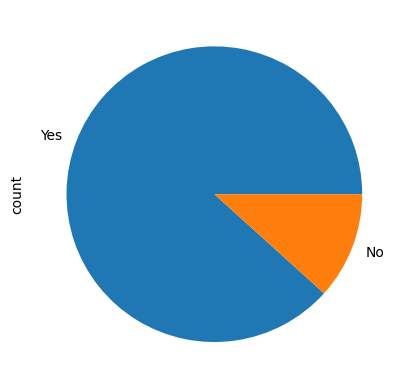

In [19]:
df['Churn'].value_counts().plot(kind='pie')

In [20]:
df.groupby("Churn")['Age'].mean()

,Age
Churn,
No,43.487179
Yes,44.831257


In [21]:
df.groupby(["Churn","Gender"])['Age'].mean()

Churn  Gender
No     Female    43.838235
       Male      43.000000
Yes    Female    45.287234
       Male      44.312349
Name: Age, dtype: float64

Text(0.5, 1.0, 'churn based on gender')

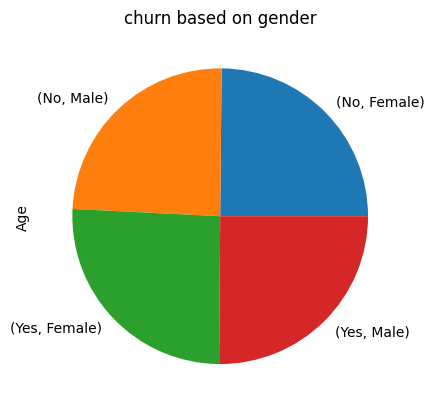

In [22]:
df.groupby(["Churn","Gender"])['Age'].mean().plot(kind="pie")
plt.title("churn based on gender")

In [23]:
df.groupby("ContractType")["MonthlyCharges"].mean()

,MonthlyCharges
ContractType,
Month-to-Month,75.909198
One-Year,73.822803
Two-Year,71.334500


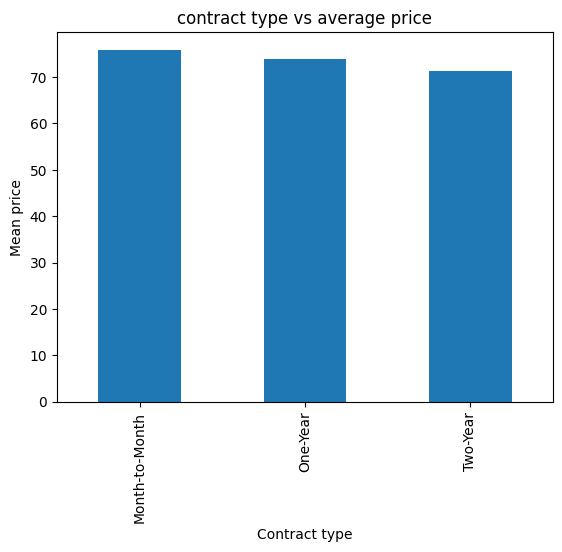

In [24]:
df.groupby("ContractType")["MonthlyCharges"].mean().plot(kind='bar')
plt.title('contract type vs average price')
plt.xlabel("Contract type")
plt.ylabel("Mean price")
plt.show()


In [25]:
df.head()

,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,42,Male,32,69.01,Month-to-Month,Fiber Optic,2208.32,No,Yes


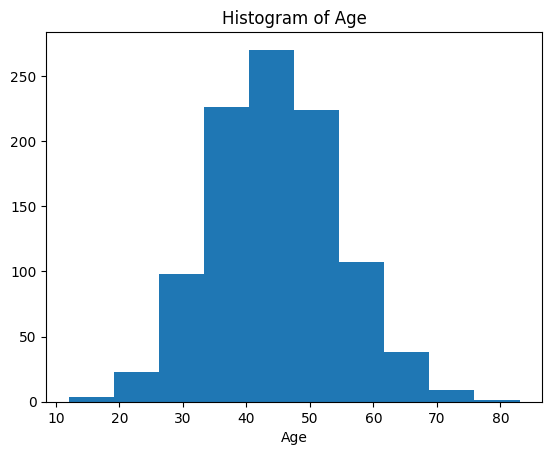

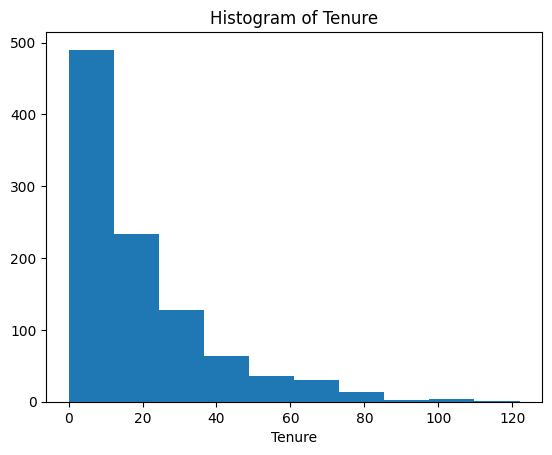

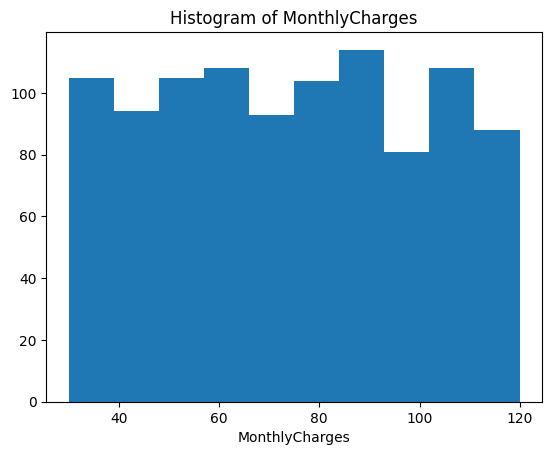

In [26]:
cols=['Age','Tenure','MonthlyCharges']
for col in cols:
    plt.hist(df[col])
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.show()

In [27]:
# Tenure is right-skewed.
#Most customers leave early, and only a small number stay for a very long time.

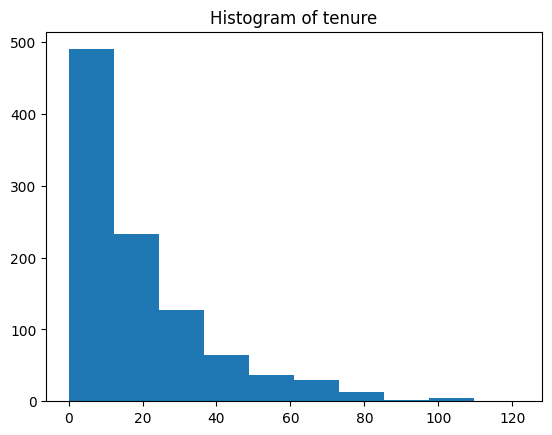

In [28]:
cols=['']
plt.hist(df["Tenure"])
plt.title("Histogram of tenure")
plt.show()


In [29]:
df.head()

,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,42,Male,32,69.01,Month-to-Month,Fiber Optic,2208.32,No,Yes


In [30]:
df.columns

Index(['Age', 'Gender', 'Tenure', 'MonthlyCharges', 'ContractType',
       'InternetService', 'TotalCharges', 'TechSupport', 'Churn'],
      dtype='object')

In [31]:
df["ContractType"].value_counts()

,count
ContractType,
Month-to-Month,511
One-Year,289
Two-Year,200


In [32]:
df["InternetService"].value_counts()

,count
InternetService,
Fiber Optic,692
DSL,308


In [33]:
df["TechSupport"].value_counts()

,count
TechSupport,
Yes,506
No,494


In [34]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

y = y.map({'Yes': 1, 'No': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

transformer = ColumnTransformer(
    transformers=[
        ('ohe',OneHotEncoder(drop='first', handle_unknown='ignore'),
         ['ContractType', 'InternetService', 'TechSupport','Gender'])
    ],remainder='passthrough'
)

X_train_tf = transformer.fit_transform(X_train)
X_test_tf  = transformer.transform(X_test)

In [36]:
transformer.fit(X_train)

feature_names = transformer.get_feature_names_out()
print(feature_names)

['ohe__ContractType_One-Year' 'ohe__ContractType_Two-Year'
 'ohe__InternetService_Fiber Optic' 'ohe__TechSupport_Yes'
 'ohe__Gender_Male' 'remainder__Age' 'remainder__Tenure'
 'remainder__MonthlyCharges' 'remainder__TotalCharges']


In [37]:
X_train_tf = transformer.fit_transform(X_train)

X_train_tf_df = pd.DataFrame(
    X_train_tf,
    columns=transformer.get_feature_names_out(),
    index=X_train.index
)

X_train_tf_df.head()

,ohe__ContractType_One-Year,ohe__ContractType_Two-Year,ohe__InternetService_Fiber Optic,ohe__TechSupport_Yes,ohe__Gender_Male,remainder__Age,remainder__Tenure,remainder__MonthlyCharges,remainder__TotalCharges
270,0.0,0.0,1.0,1.0,0.0,59.0,5.0,81.69,408.45
938,1.0,0.0,1.0,1.0,0.0,47.0,9.0,31.88,286.92
329,1.0,0.0,1.0,0.0,0.0,51.0,66.0,53.69,3543.54
886,0.0,0.0,0.0,0.0,1.0,50.0,7.0,91.40,639.80
769,0.0,0.0,1.0,0.0,0.0,63.0,6.0,39.26,235.56


In [38]:
y_train.head()

,Churn
270,1
938,1
329,1
886,1
769,1


In [39]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train_tf, y_train)
pred = gb.predict(X_test_tf)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[ 23   0]
 [  0 177]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00       177

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [40]:
gb.score(X_train_tf,y_train)

1.0

In [41]:

gb.score(X_test_tf,y_test)

1.0

In [42]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

lr  = LogisticRegression(max_iter=1000)
rf  = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
svm = SVC(probability=True)

vote = VotingClassifier(
    estimators=[("lr", lr), ("rf", rf), ("svm", svm)],
    voting="soft"
)

vote.fit(X_train_tf, y_train)
pred = vote.predict(X_test_tf)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[[ 11  12]
 [  0 177]]
              precision    recall  f1-score   support

           0       1.00      0.48      0.65        23
           1       0.94      1.00      0.97       177

    accuracy                           0.94       200
   macro avg       0.97      0.74      0.81       200
weighted avg       0.94      0.94      0.93       200



In [43]:
print(y_train.value_counts())
print(y_test.value_counts())
print(X.shape)
print(X_train.shape, X_test.shape)

Churn
1    706
0     94
Name: count, dtype: int64
Churn
1    177
0     23
Name: count, dtype: int64
(1000, 8)
(800, 8) (200, 8)


In [44]:
import pandas as pd

# Works if X_train and X_test are DataFrames
dup = pd.merge(X_train.reset_index(drop=True), X_test.reset_index(drop=True), how='inner')
print("Exact duplicate rows between train & test:", dup.shape[0])

Exact duplicate rows between train & test: 0


In [45]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# 1) Fit transformer (or use the already-fit one)
X_train_tf = transformer.fit_transform(X_train)
X_test_tf  = transformer.transform(X_test)

# 2) Fit RandomForest
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train_tf, y_train)

# 3) Now you can get feature importances
feat_names = transformer.get_feature_names_out()
imps = rf.feature_importances_

top = np.argsort(imps)[::-1][:15]
for i in top:
    print(feat_names[i], imps[i])

ohe__TechSupport_Yes 0.29710167054105496
remainder__Tenure 0.23044281781034687
remainder__MonthlyCharges 0.1204528073178281
ohe__ContractType_One-Year 0.11599587058220341
ohe__ContractType_Two-Year 0.11023409079459327
remainder__TotalCharges 0.10710280743106548
remainder__Age 0.014128490533825767
ohe__InternetService_Fiber Optic 0.002791200069108505
ohe__Gender_Male 0.001750244919973614


In [46]:
print("Train:", rf.score(X_train_tf, y_train))
print("Test :", rf.score(X_test_tf, y_test))

Train: 1.0
Test : 1.0


In [47]:
y_shuf = y_train.sample(frac=1, random_state=42).values

rf_shuf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf_shuf.fit(X_train_tf, y_shuf)

print("Shuffled-label test score:", rf_shuf.score(X_test_tf, y_test))

Shuffled-label test score: 0.885


In [48]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

cat_cols = ['ContractType','InternetService','TechSupport','Gender']
preprocess = ColumnTransformer(
    [('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)

pipe = Pipeline([
    ('prep', preprocess),
    ('rf', RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"))
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
print(scores, "mean:", scores.mean())

[1.   1.   1.   0.99 1.  ] mean: 0.998


In [49]:
from sklearn.metrics import roc_auc_score, classification_report

proba = rf.predict_proba(X_test_tf)[:,1]
print("AUC:", roc_auc_score(y_test, proba))
print(classification_report(y_test, rf.predict(X_test_tf)))

AUC: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00       177

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

